Dmitri Gomon, i.d. 304442353

## Deep Learning 22961
## Maman 13

## Im

## Imports and generic code

In [1]:
import csv
from contextlib import nullcontext
from pathlib import Path

import numpy as np
import torch
from matplotlib.ticker import MaxNLocator
from torch import nn, Tensor
from torch.optim import Optimizer
from torch.utils.data import DataLoader, random_split
from torch.utils.data import Dataset
import matplotlib.pyplot as plt

filename = "diabetes.csv"

def load_data(path: str | Path) -> list[list[str]]:
    with open(path, newline='') as csvfile:
        return list(csv.reader(csvfile, delimiter = '\t'))


def find_decile_index(decile: int, decile_ranges: list[list[int]]) -> int:
    for i in range(len(decile_ranges)):
        if decile_ranges[i][0] <= int(decile) <= decile_ranges[i][1]:
            return i
    return 0


def train_model(model: nn.Module, optimizer: Optimizer, dataloader: DataLoader,
                target_acc: float, ignore_y: bool) -> tuple[int, float | int]:
    epochs = 0
    epoch_acc = 0
    loss_fn = nn.NLLLoss()

    while epoch_acc < target_acc:
        epochs += 1
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        # run full epoch
        for features, labels in dataloader:
            optimizer.zero_grad()
            y_model = model(features) if not ignore_y else model(features[:, :-1])
            loss = loss_fn(y_model, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            predicted_labels = torch.argmax(y_model, dim=1)
            correct_predictions += (predicted_labels == labels).sum().item()
            total_samples += batch_size

        epoch_acc = correct_predictions / total_samples

    return epochs, epoch_acc


def evaluate_model(model, dataloader, ignore_y: bool) -> float:
    correct_predictions = 0
    total_samples = 0

    for features, labels in dataloader:
        batch_size = labels.size(0)
        y_model = model(features) if not ignore_y else model(features[:, :-1])
        predicted_labels = torch.argmax(y_model, dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()
        total_samples += batch_size

    return correct_predictions / total_samples

def run_epoch(model: nn.Module, dataloader: DataLoader, loss_fn: nn.Module, step: bool,
              optimizer: torch.optim.Optimizer) -> float:
    running_loss = 0.0
    total_samples = 0
    grad_ctx = nullcontext() if step else torch.no_grad()

    with grad_ctx:
        for features, targets in dataloader:
            preds = model(features).squeeze(-1)
            targets = targets.float().squeeze(-1)
            loss = loss_fn(preds, targets)

            if step:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            batch_size = targets.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

    return running_loss / total_samples


def show_graph(history: list[tuple[float, float]]) -> None:
    epochs_range = range(1, len(history) + 1)
    e_in_vals = [pair[0] for pair in history]
    e_val_vals = [pair[1] for pair in history]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(epochs_range, e_in_vals, marker="o", label="Train MSE (E_in)")
    ax.plot(epochs_range, e_val_vals, marker="s", label="Validation MSE (E_val)")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=10))
    ax.set_title("Training and Validation MSE over Epochs")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
    fig.tight_layout()
    plt.show()

## Subparagraph 3

In [2]:
def calc_ranges(data: list[list[str]], num: int):
    # read y_values (still as strings) from all rows
    y_values = [row[-1] for row in data if row]
    # convert y values to ints
    y_values = [int(y) for y in y_values]
    cutoffs = np.percentile(y_values, np.linspace(0, 100, num))
    # Consecutive pairs (low, high) form the ranges
    return list(zip(cutoffs[:-1], cutoffs[1:]))

train_data = load_data(filename)
decile_ranges = calc_ranges(train_data[1:], 11)

## Subparagraph 4

In [3]:
def add_class_col(data, decile_ranges):
    data[0].append("Class")
    for row in data[1:]:
        decile_index = find_decile_index(row[-1], decile_ranges)
        row.append(decile_index)    # 0-based decile labels [0..9]

add_class_col(train_data, decile_ranges)

## Subparagraph 5

In [4]:
class DiabetesDataset(Dataset):
    def __init__(self, rows: list[list]) -> None:
        """
        rows: data rows excluding the header row (e.g., data_loader.data[1:]).
        """

        # row[:-1] contains the feature values; row[-1] is the class label
        raw_features = torch.tensor(
            [[float(val) for val in row[:-1]] for row in rows],
            dtype=torch.float32,
        )

        # normalize data
        mean = raw_features.mean(dim=0, keepdim=True)
        std = raw_features.std(dim=0, keepdim=True, unbiased=False)
        std = torch.where(std == 0, torch.ones_like(std), std)

        self.features = (raw_features - mean) / std

        self.targets = torch.tensor(
            [int(row[-1]) for row in rows],
            dtype=torch.long,
        )

    def __len__(self) -> int:
        return self.features.size(0)

    def __getitem__(self, index: int) -> tuple[Tensor, Tensor]:
        return self.features[index], self.targets[index]

diabetes_dataset = DiabetesDataset(train_data[1:])

## Subparagraph 6

In [5]:
dataloader = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

## Subparagraph 7

In [6]:
features, targets = next(iter(dataloader))
print("features:", features)
print("targets", targets)

features: tensor([[ 0.1895, -0.9385, -0.6516,  0.4598,  0.1695,  0.1831,  0.0938, -0.0545,
          0.1983,  0.2386,  0.0242],
        [-0.5742, -0.9385, -1.3994, -2.3630, -1.0455, -0.8703,  0.0164, -0.8303,
         -0.7530, -0.1968, -0.9757],
        [ 0.1132, -0.9385, -0.7649,  0.4598,  0.0827,  0.3279,  0.1712, -0.0545,
         -0.6725, -0.9806, -0.2225],
        [ 1.4115, -0.9385,  1.1838,  1.5456, -0.2933, -0.8242, -0.6802, -0.0545,
          1.5924,  0.7611,  1.9592],
        [ 0.4187,  1.0655,  0.3001,  1.3284,  0.3141,  0.4266, -0.9899,  0.7213,
          0.9810,  1.8932,  1.8812],
        [ 0.1132, -0.9385,  1.2291, -0.9154, -1.5372, -1.5221,  0.4034, -1.6061,
         -1.0807, -0.5452, -0.2095],
        [ 0.6478, -0.9385,  0.8439,  1.6179,  0.3720,  0.7953, -0.6028,  0.7213,
         -0.0315,  2.5027,  0.0372],
        [ 0.3423, -0.9385,  0.3680, -0.4811,  1.2688,  0.9336,  0.6356, -0.0545,
          0.7828, -0.0227, -0.3134],
        [ 0.2659,  1.0655,  0.0508,  1.1837,  

## Subparagraph 8

In [7]:
dataloader_a = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

model_a = nn.Sequential(
    nn.Linear(11, 11),
    nn.ReLU(),
    nn.Linear(11, 10),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)

epochs_a, acc_in_a = train_model(model = model_a, optimizer=optimizer_a, dataloader=dataloader_a,
                                      target_acc= 0.1, ignore_y=False)

print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_in={acc_in_a:.4f}")

[model_a | ignore_y=False] epochs=3 |  acc_in=0.1109


## Subparagraph 9

In [8]:
dataloader_b = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

model_b = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 10),
    nn.LogSoftmax(dim=1),
)

optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

epochs_b, acc_in_b = train_model(model = model_b, optimizer=optimizer_b, dataloader=dataloader_b,
                                      target_acc= 0.1, ignore_y=True)
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_in={acc_in_b:.4f}")



[model_b | ignore_y=True] epochs=2 |  acc_in=0.1063


## Subparagraph 10

In [9]:
# 10
train_ds, test_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=True)
test_dataloader = DataLoader(test_ds,  batch_size=10, shuffle=True)

model_a = nn.Sequential(
    nn.Linear(11, 11),
    nn.ReLU(),
    nn.Linear(11, 10),
    nn.LogSoftmax(dim=1),
)

model_b = nn.Sequential(
    nn.Linear(10, 10),
    nn.ReLU(),
    nn.Linear(10, 10),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)
optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

n_runs = 100
acc_out_a = 0.0
acc_out_b = 0.0

for i in range(n_runs):
    epochs_a, acc_in_a = train_model(model_a, optimizer_a, train_dataloader,  0.1, False)
    epochs_b, acc_in_b = train_model(model_b, optimizer_b, train_dataloader,  0.1, True)

    acc_out_a += evaluate_model(model = model_a, dataloader=test_dataloader, ignore_y=False)
    acc_out_b += evaluate_model(model= model_b, dataloader=test_dataloader, ignore_y= True)

acc_out_a /= n_runs
acc_out_b /= n_runs

print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_out={acc_out_a:.4f}")
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_out={acc_out_b:.4f}")

[model_a | ignore_y=False] epochs=1 |  acc_out=0.3614
[model_b | ignore_y=True] epochs=1 |  acc_out=0.2058


## Subparagraph 11
Across 100 runs evaluated on the 20% test set, network A trained with Y included achieves a substantially higher mean accuracy than network B trained without Y. Because Class is defined directly by the decile intervals of Y, providing Y gives the network direct access to the variable that determines the class boundaries. When Y is excluded, the network must rely on the remaining features, which only partially and noisily reflect Y's decile thresholds, resulting in lower classification accuracy.

## Subparagraph 12

In [10]:
train_data = load_data(filename)
percentile_ranges = calc_ranges(train_data[1:], num = 101)
add_class_col(train_data, percentile_ranges)

## Subparagraph 13 (8)

In [11]:
diabetes_dataset = DiabetesDataset(train_data[1:])
dataloader_a = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

model_a = nn.Sequential(
    nn.Linear(11, 50),
    nn.ReLU(),
    nn.Linear(50, 100),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)

epochs_a, acc_in_a = train_model(model = model_a, optimizer=optimizer_a, dataloader=dataloader_a,
                                      target_acc= 0.005, ignore_y=False)
print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_in={acc_in_a:.4f}")

[model_a | ignore_y=False] epochs=1 |  acc_in=0.0226


## Subparagraph 13 (9)

In [12]:
dataloader_b = DataLoader(diabetes_dataset,  batch_size=10, shuffle=True)

model_b = nn.Sequential(
    nn.Linear(10, 50),
    nn.ReLU(),
    nn.Linear(50, 100),
    nn.LogSoftmax(dim=1),
)

optimizer_b = torch.optim.SGD(model_a.parameters(), lr=0.01)

epochs_b, acc_in_b = train_model(model = model_b, optimizer=optimizer_b, dataloader=dataloader_b,
                                      target_acc= 0.005, ignore_y=True)
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_in={acc_in_b:.4f}")

[model_b | ignore_y=True] epochs=1 |  acc_in=0.0136


## Subparagraph 13 (10)

In [13]:
train_ds, test_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=True)
test_dataloader = DataLoader(test_ds,  batch_size=10, shuffle=True)

model_a = nn.Sequential(
    nn.Linear(11, 50),
    nn.ReLU(),
    nn.Linear(50, 100),
    nn.LogSoftmax(dim=1),
)

model_b = nn.Sequential(
    nn.Linear(10, 50),
    nn.ReLU(),
    nn.Linear(50, 100),
    nn.LogSoftmax(dim=1),
)

optimizer_a = torch.optim.SGD(model_a.parameters(), lr=0.01)
optimizer_b = torch.optim.SGD(model_b.parameters(), lr=0.01)

n_runs = 100
acc_out_a = 0.0
acc_out_b = 0.0

for i in range(n_runs):
    epochs_a, acc_in_a = train_model(model_a, optimizer_a, train_dataloader,  0.005, False)
    epochs_b, acc_in_b = train_model(model_b, optimizer_b, train_dataloader,  0.001, True)

    acc_out_a += evaluate_model(model = model_a, dataloader=test_dataloader, ignore_y=False)
    acc_out_b += evaluate_model(model= model_b, dataloader=test_dataloader, ignore_y= True)

acc_out_a /= n_runs
acc_out_b /= n_runs

print(f"[model_a | ignore_y=False] epochs={epochs_a} |  acc_out={acc_out_a:.4f}")
print(f"[model_b | ignore_y=True] epochs={epochs_b} |  acc_out={acc_out_b:.4f}")


[model_a | ignore_y=False] epochs=1 |  acc_out=0.0111
[model_b | ignore_y=True] epochs=1 |  acc_out=0.0170


## Subparagraph 14

I would prefer deciles over percentiles for the following reasons:

* **Sample density: ** Deciles yield $\approx$ 44 samples per class ($\approx$ 35 train, $\approx$9 test), whereas percentiles yield only $\approx$4–5 samples per class overall (<1 per class in the test set), causing sparse or empty mini-batches.
* **Boundary stability:** Narrow 1% bins introduce high label noise from small changes in `Y`, while wider 10% intervals provide cleaner decision boundaries.
* **Evaluation reliability:** Accuracy across 10 classes has much lower variance on an $\approx$88-sample test split than across 100 classes (continuous precision is better handled via regression).

## Subparagraph 15

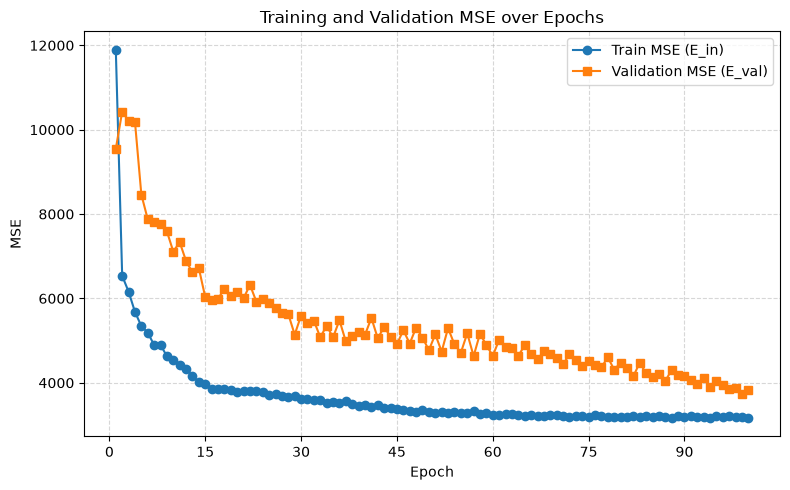

In [14]:
train_data = load_data(filename)
diabetes_dataset = DiabetesDataset(train_data[1:])

train_ds, val_ds = random_split(dataset=diabetes_dataset,
                                 lengths=[0.8, 0.2], generator=torch.Generator().manual_seed(42))

train_dataloader = DataLoader(train_ds,  batch_size=10, shuffle=False)
val_dataloader = DataLoader(val_ds,  batch_size=10, shuffle=False)

model = nn.Sequential(
    nn.Linear(10, 5),
    nn.ReLU(),
    nn.Linear(5, 1),
)
optimizer = torch.optim.SGD(model.parameters(), lr=0.002)

n_epochs = 100
loss_fn = nn.MSELoss()
history: list[tuple[float, float]] = []

for epoch in range(n_epochs):
    e_in = run_epoch(model, train_dataloader, loss_fn, True, optimizer)
    e_val = run_epoch(model, val_dataloader, loss_fn, False, None)
    history.append((e_in, e_val))

show_graph(history)
